<a href="https://colab.research.google.com/github/abdulghaffark2425/Datheon_Python_Programming_Internship/blob/main/Task01_MultiClass_Benchmark_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Step 1: Loading Dataset ===
Loaded dataset directly from scikit-learn benchmark fallback.
Dataset Shape: (150, 5)

Dataset Head:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

=== Step 2: Exploratory Data Visualizations ===


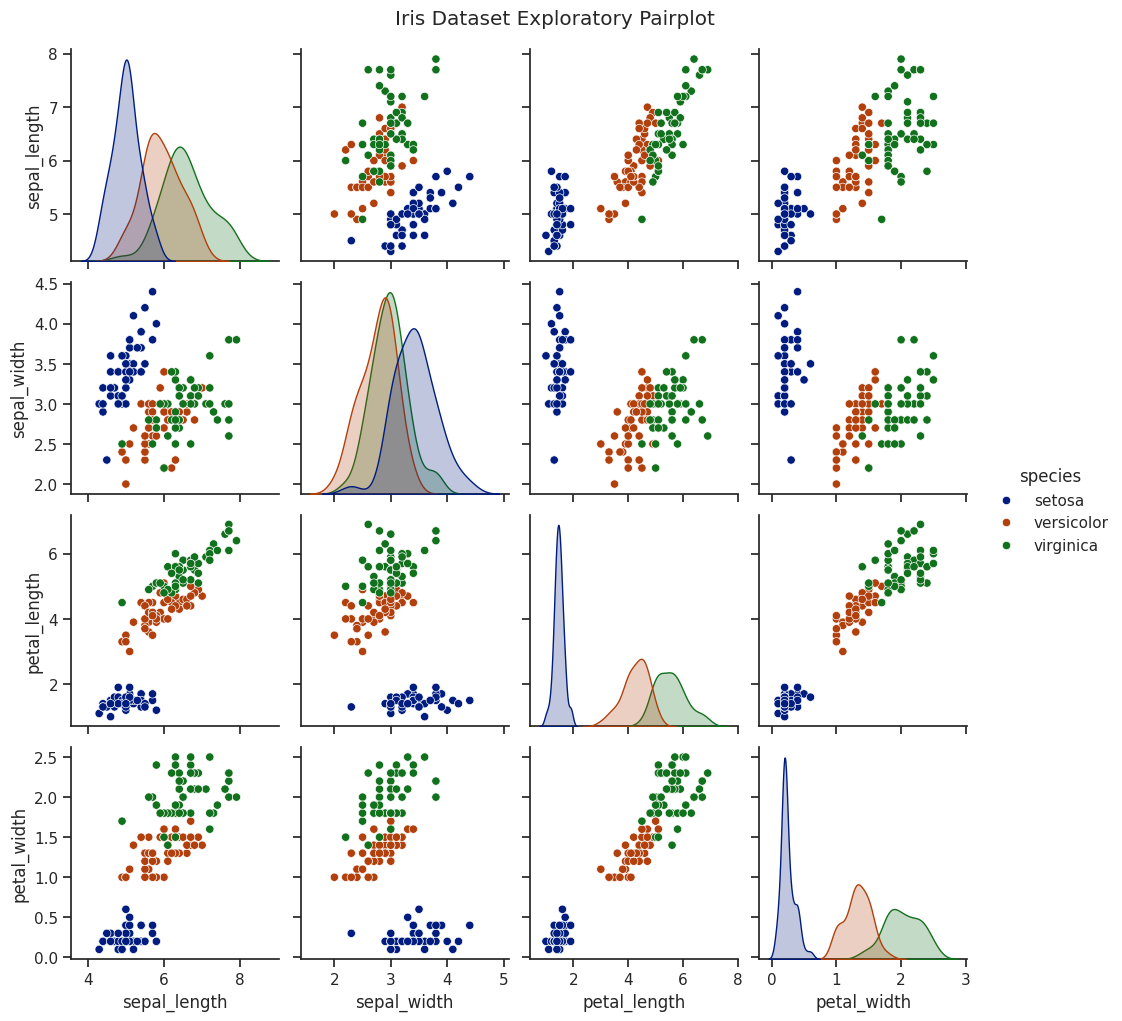


=== Step 3: Dataset Splitting & Standard Scaling ===
Training set: 120 samples | Testing set: 30 samples

=== Step 4: Model Training ===

=== Step 5: Classification Reports & Metrics ===
--- 1. Logistic Regression Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

--- 2. Decision Tree Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97  

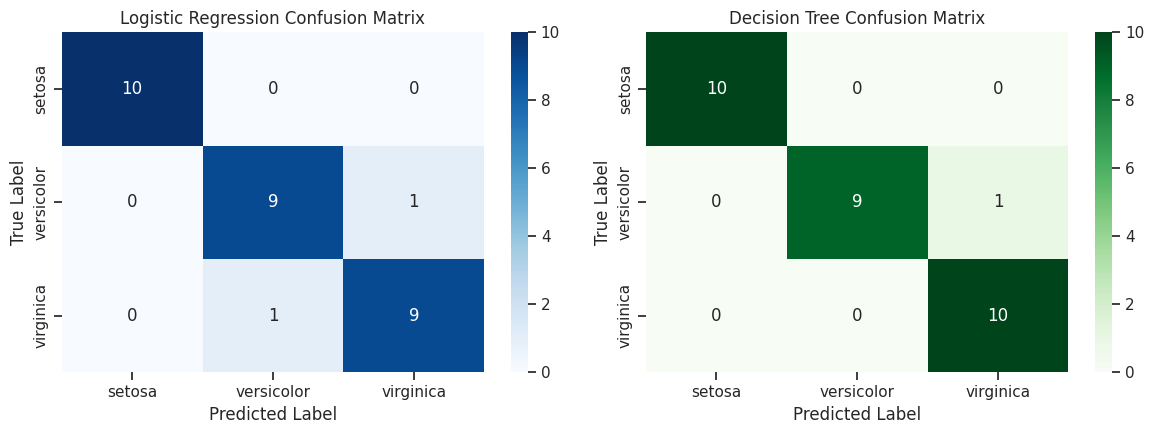


=== Step 7: Decision Boundary Visualization ===


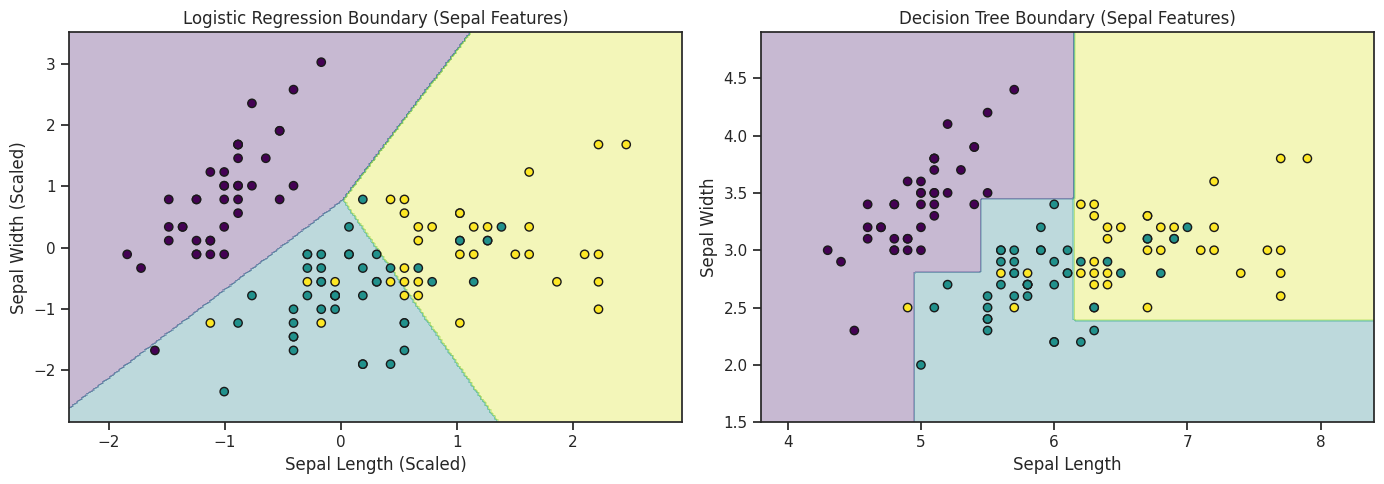

In [1]:
# =========================================================
# DATHEON ML INTERNSHIP - TASK 01
# Multi-Class Benchmark Classification Pipeline (Iris)
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# ---------------------------------------------------------
# STEP 1: Load Dataset (CSV Upload ya Direct Fallback)
# ---------------------------------------------------------
print("=== Step 1: Loading Dataset ===")
try:
    df = pd.read_csv('iris.csv')
    print("Loaded dataset successfully from 'iris.csv'")
except FileNotFoundError:
    from sklearn.datasets import load_iris
    iris_raw = load_iris()
    df = pd.DataFrame(iris_raw.data, columns=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'])
    df['species'] = pd.Series(iris_raw.target).map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
    print("Loaded dataset directly from scikit-learn benchmark fallback.")

print("Dataset Shape:", df.shape)
print("\nDataset Head:")
print(df.head())

X = df.drop(columns=['species'])
y = df['species']

# Map string labels to numeric for internal plotting consistency
species_map = {name: idx for idx, name in enumerate(y.unique())}
y_numeric = y.map(species_map)

# ---------------------------------------------------------
# STEP 2: Exploratory Pairplots with Seaborn
# ---------------------------------------------------------
print("\n=== Step 2: Exploratory Data Visualizations ===")
sns.set_theme(style="ticks")
sns.pairplot(df, hue="species", palette="dark", diag_kind="kde")
plt.suptitle("Iris Dataset Exploratory Pairplot", y=1.02)
plt.show()

# ---------------------------------------------------------
# STEP 3: Train / Test Split (80/20) & Feature Scaling
# ---------------------------------------------------------
print("\n=== Step 3: Dataset Splitting & Standard Scaling ===")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape[0]} samples | Testing set: {X_test.shape[0]} samples")

# ---------------------------------------------------------
# STEP 4: Model Training (Logistic Regression & Decision Tree)
# ---------------------------------------------------------
print("\n=== Step 4: Model Training ===")

# Model A: Logistic Regression (Scaled Features)
lr_model = LogisticRegression(random_state=42, max_iter=200)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

# Model B: Decision Tree Classifier (Raw Features)
dt_model = DecisionTreeClassifier(random_state=42, max_depth=3)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# ---------------------------------------------------------
# STEP 5: Classification Reports & Benchmark Metrics
# ---------------------------------------------------------
print("\n=== Step 5: Classification Reports & Metrics ===")

print("--- 1. Logistic Regression Report ---")
print(classification_report(y_test, y_pred_lr))

print("--- 2. Decision Tree Report ---")
print(classification_report(y_test, y_pred_dt))

# ---------------------------------------------------------
# STEP 6: Confusion Matrix Heatmaps
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = sorted(y.unique())

sns.heatmap(confusion_matrix(y_test, y_pred_lr, labels=labels),
            annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(confusion_matrix(y_test, y_pred_dt, labels=labels),
            annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title("Decision Tree Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# STEP 7: Decision Boundary Visualizations (2D Projection)
# ---------------------------------------------------------
print("\n=== Step 7: Decision Boundary Visualization ===")

X_2d = X.iloc[:, :2].values  # First two features: sepal_length, sepal_width
y_2d = y_numeric.values

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d, test_size=0.20, random_state=42, stratify=y_2d
)

scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

lr_2d = LogisticRegression(random_state=42).fit(X_train_2d_scaled, y_train_2d)
dt_2d = DecisionTreeClassifier(random_state=42, max_depth=3).fit(X_train_2d, y_train_2d)

def plot_boundary(model, X_data, y_data, title, ax, is_scaled=False):
    h = 0.02
    x_min, x_max = X_data[:, 0].min() - 0.5, X_data[:, 0].max() + 0.5
    y_min, y_max = X_data[:, 1].min() - 0.5, X_data[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    mesh_data = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(mesh_data)
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    scatter = ax.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap='viridis', edgecolors='k')
    ax.set_title(title)
    ax.set_xlabel("Sepal Length" if not is_scaled else "Sepal Length (Scaled)")
    ax.set_ylabel("Sepal Width" if not is_scaled else "Sepal Width (Scaled)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_boundary(lr_2d, X_train_2d_scaled, y_train_2d, "Logistic Regression Boundary (Sepal Features)", axes[0], is_scaled=True)
plot_boundary(dt_2d, X_train_2d, y_train_2d, "Decision Tree Boundary (Sepal Features)", axes[1], is_scaled=False)
plt.tight_layout()
plt.show()